# 01｜EEG 数据读取、预处理与 PSD 分析

使用 PhysioNet EEGBCI 公开数据（受试者 1，run 6）演示数据读取、EEG 通道筛选、1–40 Hz 滤波、PSD 计算与结果保存。

**运行说明**
- 本 Notebook 应放在 `Project_01_EEG_Preprocessing_PSD/notebooks/` 中。
- 输入数据下载到本项目的 `data/eeg_data/`。
- 本项目生成的图和结果分别保存到本项目的 `figures/` 与 `results/`。
- 首次运行需要联网下载公开数据。


In [1]:
from pathlib import Path
import json
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 自动定位 Project 01 根目录，不依赖 Jupyter 当前工作目录
expected_name = "Project_01_EEG_Preprocessing_PSD"
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
PROJECT_DIR = next((p for p in candidates if p.name == expected_name), None)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        f"没有找到项目目录 {expected_name}。"
        "请将 Notebook 放在该项目的 notebooks 文件夹中运行。"
    )

DATA_DIR = PROJECT_DIR / "data" / "eeg_data"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

for folder in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("项目目录：", PROJECT_DIR)
print("MNE版本：", mne.__version__)

# 下载公开 EEG 数据：PhysioNet EEGBCI，受试者1，run6
data_path = mne.datasets.eegbci.load_data(
    subjects=[1],
    runs=[6],
    path=str(DATA_DIR)
)

print("下载/读取到的文件：", data_path)

# 读取 EDF
raw = mne.io.read_raw_edf(data_path[0], preload=True, verbose=False)

print("\n===== 原始数据信息 =====")
print(raw)

sfreq = raw.info["sfreq"]
n_channels = len(raw.ch_names)
duration_sec = raw.n_times / sfreq
duration_min = duration_sec / 60

print("\n采样率：", sfreq, "Hz")
print("通道数：", n_channels)
print("时长：", round(duration_sec, 2), "秒")
print("时长：", round(duration_min, 2), "分钟")
print("前10个通道：", raw.ch_names[:10])

# 只保留 EEG 通道
raw_eeg = raw.copy().pick("eeg")

print("\n===== EEG通道信息 =====")
print("EEG通道数：", len(raw_eeg.ch_names))
print("EEG通道：", raw_eeg.ch_names)

overview = {
    "file": str(data_path[0]),
    "sfreq_hz": float(sfreq),
    "n_channels_total": int(n_channels),
    "n_channels_eeg": int(len(raw_eeg.ch_names)),
    "duration_sec": float(duration_sec),
    "duration_min": float(duration_min),
    "eeg_channels": raw_eeg.ch_names,
}

with open(RESULTS_DIR / "day1_data_overview.txt", "w", encoding="utf-8") as f:
    for k, v in overview.items():
        f.write(f"{k}: {v}\n")

print("\n已保存：", RESULTS_DIR / "day1_data_overview.txt")


项目目录： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_01_EEG_Preprocessing_PSD
MNE版本： 1.12.1


Do you want to set the path:
    C:\Users\Administrator\EEG-Analysis-Portfolio\Project_01_EEG_Preprocessing_PSD\data\eeg_data
as the default EEGBCI dataset path in the mne-python config [y]/n?  y


Download complete in 52s (2.5 MB)
下载/读取到的文件： [WindowsPath('C:/Users/Administrator/EEG-Analysis-Portfolio/Project_01_EEG_Preprocessing_PSD/data/eeg_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R06.edf')]

===== 原始数据信息 =====
<RawEDF | S001R06.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>

采样率： 160.0 Hz
通道数： 64
时长： 125.0 秒
时长： 2.08 分钟
前10个通道： ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..']

===== EEG通道信息 =====
EEG通道数： 64
EEG通道： ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.', 'Cp3.', 'Cp1.', 'Cpz.', 'Cp2.', 'Cp4.', 'Cp6.', 'Fp1.', 'Fpz.', 'Fp2.', 'Af7.', 'Af3.', 'Afz.', 'Af4.', 'Af8.', 'F7..', 'F5..', 'F3..', 'F1..', 'Fz..', 'F2..', 'F4..', 'F6..', 'F8..', 'Ft7.', 'Ft8.', 'T7..', 'T8..', 'T9..', 'T10.', 'Tp7.', 'Tp8.', 'P7..', 'P5..', 'P3..', 'P1..', 'Pz..', 'P2..', 'P4..', 'P6..', 'P8..', 'Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..', 'Iz..']

已保存： C:\Users\

In [2]:
l_freq = 1.0
h_freq = 40.0

raw_filtered = raw_eeg.copy().filter(
    l_freq=l_freq,
    h_freq=h_freq,
    fir_design="firwin",
    verbose=False
)

print("滤波完成：", l_freq, "-", h_freq, "Hz")

滤波完成： 1.0 - 40.0 Hz


In [3]:
spectrum = raw_filtered.compute_psd(
    fmin=1,
    fmax=40,
    n_fft=256,
    verbose=False
)

psds, freqs = spectrum.get_data(return_freqs=True)

print("PSD形状：", psds.shape)
print("频率点数量：", len(freqs))
print("频率范围：", freqs[0], "-", freqs[-1], "Hz")

PSD形状： (64, 63)
频率点数量： 63
频率范围： 1.25 - 40.0 Hz


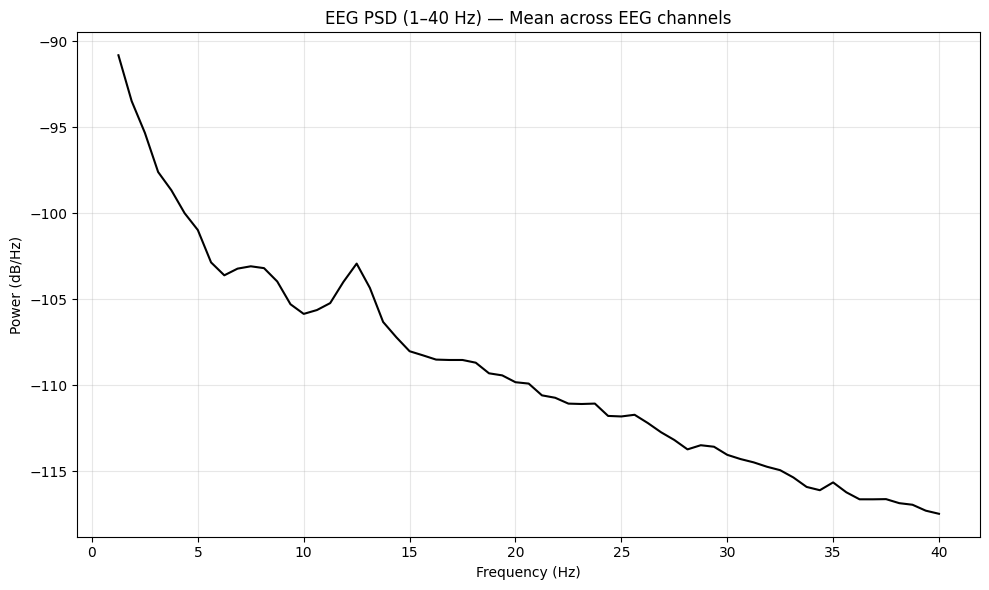

已保存： C:\Users\Administrator\EEG-Analysis-Portfolio\Project_01_EEG_Preprocessing_PSD\figures\psd.png


In [4]:
mean_psd = psds.mean(axis=0)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(freqs, 10 * np.log10(mean_psd), color="black", linewidth=1.5)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power (dB/Hz)")
ax.set_title("EEG PSD (1–40 Hz) — Mean across EEG channels")
ax.grid(True, alpha=0.3)
plt.tight_layout()

psd_figure_path = FIGURES_DIR / "psd.png"
plt.savefig(psd_figure_path, dpi=150)
plt.show()

print("已保存：", psd_figure_path)


In [5]:
raw_filtered_path = RESULTS_DIR / "EEG_filtered_raw.fif"

raw_filtered.save(
    str(raw_filtered_path),
    overwrite=True,
    verbose=False
)

params = {
    "input_file": str(data_path[0]),
    "sfreq_hz": float(raw.info["sfreq"]),
    "n_channels": int(len(raw_eeg.ch_names)),
    "l_freq_hz": l_freq,
    "h_freq_hz": h_freq,
    "filter_design": "firwin",
    "psd_fmin": 1,
    "psd_fmax": 40,
    "psd_n_fft": 256,
    "output_file": str(raw_filtered_path),
}

with open(RESULTS_DIR / "params_project01.json", "w", encoding="utf-8") as f:
    json.dump(params, f, indent=2, ensure_ascii=False)

print("已保存：")
print("-", raw_filtered_path)
print("-", RESULTS_DIR / "params_project01.json")
print(json.dumps(params, indent=2, ensure_ascii=False))


已保存：
- C:\Users\Administrator\EEG-Analysis-Portfolio\Project_01_EEG_Preprocessing_PSD\results\EEG_filtered_raw.fif
- C:\Users\Administrator\EEG-Analysis-Portfolio\Project_01_EEG_Preprocessing_PSD\results\params_project01.json
{
  "input_file": "C:\\Users\\Administrator\\EEG-Analysis-Portfolio\\Project_01_EEG_Preprocessing_PSD\\data\\eeg_data\\MNE-eegbci-data\\files\\eegmmidb\\1.0.0\\S001\\S001R06.edf",
  "sfreq_hz": 160.0,
  "n_channels": 64,
  "l_freq_hz": 1.0,
  "h_freq_hz": 40.0,
  "filter_design": "firwin",
  "psd_fmin": 1,
  "psd_fmax": 40,
  "psd_n_fft": 256,
  "output_file": "C:\\Users\\Administrator\\EEG-Analysis-Portfolio\\Project_01_EEG_Preprocessing_PSD\\results\\EEG_filtered_raw.fif"
}


In [6]:
for folder in [RESULTS_DIR, FIGURES_DIR]:
    print(f"\n{folder.name}:")
    for file in sorted(folder.iterdir()):
        if file.is_file():
            print(" -", file.name)



results:
 - day1_data_overview.txt
 - EEG_filtered_raw.fif
 - params_project01.json

figures:
 - psd.png


In [7]:
# 重新读取并检查本项目保存的滤波文件
file_path = RESULTS_DIR / "EEG_filtered_raw.fif"

raw_check = mne.io.read_raw_fif(
    str(file_path),
    preload=False,
    verbose=False
)

print("===== EEG 文件重新读取检查 =====")
print("采样率：", raw_check.info["sfreq"])
print("通道数：", len(raw_check.ch_names))
print("采样点数：", raw_check.n_times)
print("数据时长：", raw_check.n_times / raw_check.info["sfreq"])
print("高通滤波：", raw_check.info["highpass"])
print("低通滤波：", raw_check.info["lowpass"])
print("文件是否存在：", file_path.exists())


===== EEG 文件重新读取检查 =====
采样率： 160.0
通道数： 64
采样点数： 20000
数据时长： 125.0
高通滤波： 1.0
低通滤波： 40.0
文件是否存在： True


In [9]:
import os

project_dir = r"C:\Users\Administrator\EEG-Analysis-Portfolio\Project_01_EEG_Preprocessing_PSD"

print("===== Project 01 文件检查 =====")

for folder in ["results", "figures"]:
    folder_path = os.path.join(project_dir, folder)

    print(f"\n[{folder}]")

    if os.path.exists(folder_path):
        for file in os.listdir(folder_path):
            print(file)
    else:
        print("目录不存在")

===== Project 01 文件检查 =====

[results]
day1_data_overview.txt
EEG_filtered_raw.fif
params_project01.json

[figures]
psd.png
